Import knihoven

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

test na grafickou kartu (nvidia) - nahoře: běh, změnit typ běhového prostředí

In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


načtení datasetu MNIST

In [17]:
# Transformace obrázků do tensorů a normalizace hodnot na interval [0, 1]
transform = transforms.ToTensor()

# Načtení datasetu
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print(f"\nTraining samples: {len(train_dataset)}")
print(f"Testing samples: {len(test_dataset)}")


Training samples: 60000
Testing samples: 10000


zobrazíme prvních 5 řádků

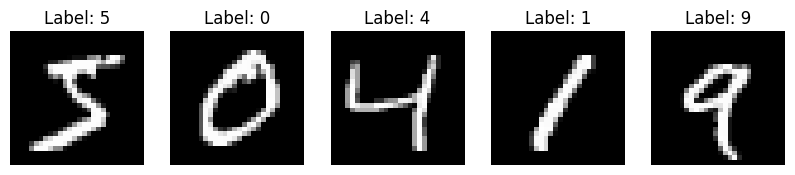

In [18]:
plt.figure(figsize=(10, 5))

for i in range(5):
    image, label = train_dataset[i]

    plt.subplot(1, 5, i + 1)
    plt.imshow(image.squeeze() , cmap="gray") # image squeeze změní tenzor obrázku z torch.Size([1, 28, 28]) na torch.Size([28, 28])
    plt.title(f"Label: {label}")
    plt.axis("off")

plt.show()

rozdělíme trénovací dataset na 80% trénovacích dat a 20% validačních dat

In [19]:
# Rozdělení datasetu
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# DataLoadery
batch_size = 32

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print(f"Training: {len(train_subset)}")
print(f"Validation: {len(val_subset)}")
print(f"Testing: {len(test_dataset)}")

Training: 48000
Validation: 12000
Testing: 10000


??? proč testing tak málo

vytvoření neuronové sítě

In [20]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


# Vytvoření modelu
model = NeuralNetwork().to(device)

print(model)

NeuralNetwork(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


nastavení loss funkce a optimalizátoru

In [21]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

parametry modelu

In [ ]:
try:
    from torchinfo import summary
except ImportError:
    !pip install -q torchinfo
    from torchinfo import summary

summary(model, input_size=(1, 1, 28, 28))

trénování neuronové sítě

In [23]:
# casovac a jeho start
import time
start_time = time.time()

epochs = 10

history = {
    "accuracy": [],
    "val_accuracy": [],
    "loss": [],
    "val_loss": []
}

for epoch in range(epochs):

    # TRAINING
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Vynulování gradientů
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Výpočet chyby
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Aktualizace vah
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # VALIDATION
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # Uložení historie
    history["loss"].append(train_loss)
    history["accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Accuracy: {train_accuracy:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

# Výpočet celkové doby
end_time = time.time()
total_time = end_time - start_time

print(f"\nTraining time: {total_time:.2f} seconds")

Epoch [1/10] Train Loss: 0.3238, Train Accuracy: 0.9048, Val Loss: 0.1844, Val Accuracy: 0.9456
Epoch [2/10] Train Loss: 0.1316, Train Accuracy: 0.9609, Val Loss: 0.1323, Val Accuracy: 0.9589
Epoch [3/10] Train Loss: 0.0890, Train Accuracy: 0.9726, Val Loss: 0.1148, Val Accuracy: 0.9648
Epoch [4/10] Train Loss: 0.0673, Train Accuracy: 0.9791, Val Loss: 0.1002, Val Accuracy: 0.9710
Epoch [5/10] Train Loss: 0.0522, Train Accuracy: 0.9838, Val Loss: 0.0879, Val Accuracy: 0.9731
Epoch [6/10] Train Loss: 0.0418, Train Accuracy: 0.9866, Val Loss: 0.0993, Val Accuracy: 0.9709
Epoch [7/10] Train Loss: 0.0334, Train Accuracy: 0.9892, Val Loss: 0.1083, Val Accuracy: 0.9697
Epoch [8/10] Train Loss: 0.0283, Train Accuracy: 0.9907, Val Loss: 0.0886, Val Accuracy: 0.9747
Epoch [9/10] Train Loss: 0.0217, Train Accuracy: 0.9929, Val Loss: 0.1098, Val Accuracy: 0.9713
Epoch [10/10] Train Loss: 0.0204, Train Accuracy: 0.9936, Val Loss: 0.1092, Val Accuracy: 0.9725

Training time: 135.23 seconds


vizualizace průběhu trénování

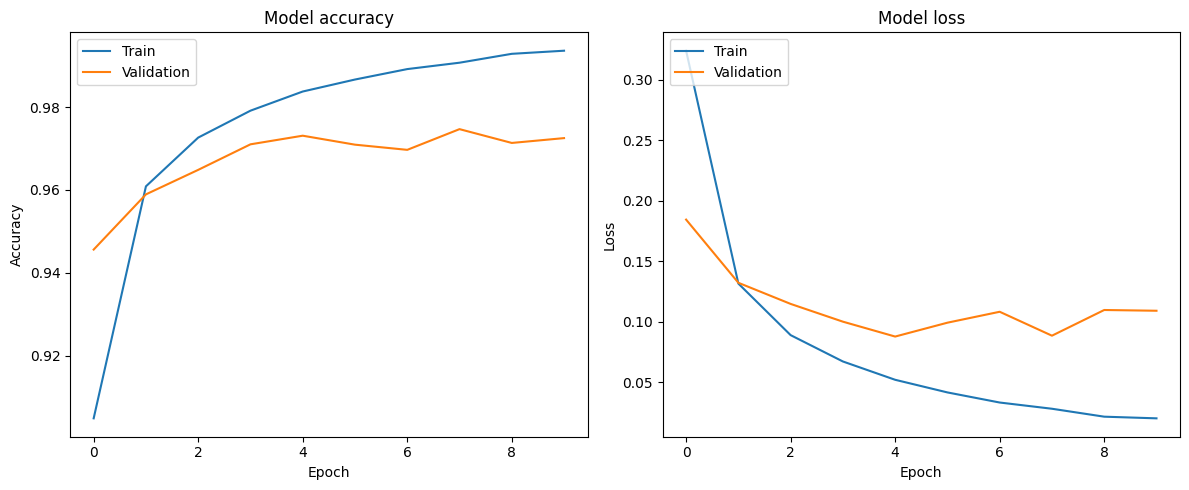

In [24]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history["accuracy"], label="Train")
plt.plot(history["val_accuracy"], label="Validation")

plt.title("Model accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(loc="upper left")

# Loss
plt.subplot(1, 2, 2)

plt.plot(history["loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")

plt.title("Model loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(loc="upper left")

plt.tight_layout()
plt.show()

predikce na prvních 5ti testovacích obrázcích

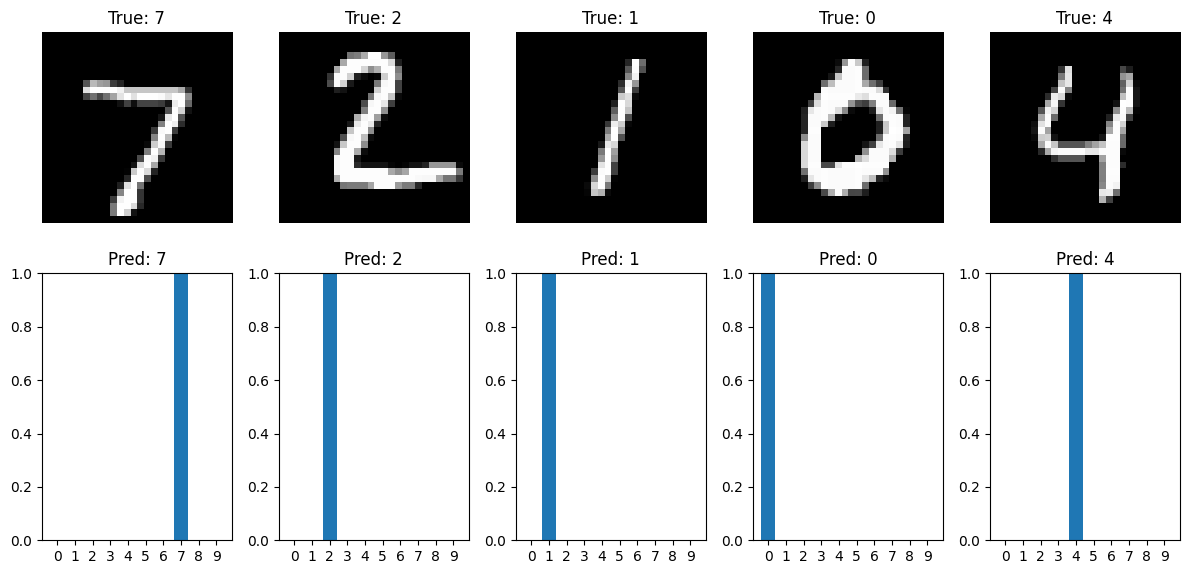

In [25]:
model.eval()

plt.figure(figsize=(12, 6))

with torch.no_grad():
    for i in range(5):

        image, true_label = test_dataset[i]

        input_image = image.unsqueeze(0).to(device)

        outputs = model(input_image)

        probabilities = torch.softmax(outputs, dim=1)

        predicted_label = torch.argmax(probabilities, dim=1).item()

        # Zobrazení obrázku
        plt.subplot(2, 5, i + 1)
        plt.imshow(image.squeeze(), cmap="gray")
        plt.title(f"True: {true_label}")
        plt.axis("off")

        # Zobrazení pravděpodobností
        plt.subplot(2, 5, i + 6)

        plt.bar(
            range(10),
            probabilities.cpu().numpy()[0]
        )

        plt.xticks(range(10))
        plt.title(f"Pred: {predicted_label}")
        plt.ylim(0, 1)

plt.tight_layout()
plt.show()

nahrání vlastního obrázku

In [ ]:
from google.colab import files

uploaded = files.upload()

# Získání názvu prvního nahraného souboru
image_path = next(iter(uploaded))

print("Nahraný soubor:", image_path)

načtení vlastního obrázku

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(image_path)

plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

predikce vlastního obrázku

In [ ]:
try:
    # Načtení obrázku jako grayscale
    img = Image.open(image_path).convert("L")

    # Změna velikosti na 28x28
    img = img.resize((28, 28))

    # Převod na numpy array
    img_array = np.array(img).astype("float32") / 255.0

    # Inverze barev
    img_array = 1.0 - img_array

    # Převod na PyTorch tensor
    img_tensor = torch.tensor(img_array, dtype=torch.float32)

    # Přidání batch a channel dimenze
    # (28, 28) -> (1, 1, 28, 28)
    img_tensor = img_tensor.unsqueeze(0).unsqueeze(0)

    img_tensor = img_tensor.to(device)

    # Predikce
    model.eval()

    with torch.no_grad():
        outputs = model(img_tensor)

        probabilities = torch.softmax(outputs, dim=1)

        predicted_label = torch.argmax(
            probabilities, dim=1
        ).item()

    print(f"Predicted digit for {image_path}: {predicted_label}")

    # Zobrazení obrázku
    plt.figure(figsize=(4, 4))

    plt.imshow(img_array, cmap="gray")

    plt.title(
        f"Processed and Inverted Image\n"
        f"Predicted: {predicted_label}"
    )

    plt.axis("off")
    plt.show()

except FileNotFoundError:
    print(f"Error: File '{image_path}' was not found.")

except Exception as e:
    print(f"An error occurred: {e}")

uložení modelu

In [ ]:
torch.save(model.state_dict(), "mnist_ann.pth")

pozdější načtení modelu

In [ ]:
model = NeuralNetwork().to(device)

model.load_state_dict(
    torch.load("mnist_ann.pth", map_location=device, weights_only=True)
)

model.eval()